In [51]:
import pip
!pip install xgboost
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix, precision_recall_curve, classification_report
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier,
                              HistGradientBoostingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import RidgeClassifier, SGDClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB

In [52]:
#Loading Data
df = pd.read_excel("Telco_customer_churn.xlsx")
df.shape

Task was destroyed but it is pending!
task: <Task pending name='Task-244' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\anish\AppData\Roaming\Python\Python314\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-245' coro=<Kernel.shell_main() running at C:\Users\anish\AppData\Roaming\Python\Python314\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\anish\AppData\Roaming\Python\Python314\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\anish\anaconda3\Lib\xml\etree\ElementTree.py:1675: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  return self.target.start(tag, attrib)
Task was destroyed but it is pending!
task: <Task pending name='Task-245' coro=<Kernel.shell_main() running at C:\Users\anish\AppData\Roaming\Python\Python314\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>


(7043, 33)

In [53]:
#Creating Duplicate data
df_copy = df.copy()

In [54]:
#Dropping Unnecessary Columns
df_copy = df_copy.drop(columns=["Country", "State", "CustomerID", "Count", "Churn Reason", "City", "Zip Code", "Churn Score", "Churn Label", "Lat Long","CLTV"])

In [55]:
#Converting Values into int
df_copy["Total Charges"] = pd.to_numeric(df_copy["Total Charges"], errors="coerce").fillna(0)

In [56]:
#Splitting data into Target and Features
X = df_copy.drop(columns=["Churn Value"])
y = df_copy["Churn Value"]

In [57]:
#Classifying Numerical and Categorical Columns
int_cols = X.select_dtypes(include=["int","float"]).columns.tolist()
other_cols = X.select_dtypes(exclude=["int","float"]).columns.tolist()
print(len(int_cols))
print(len(other_cols))

5
16


In [58]:
#Splitting Training and Testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [59]:
#Generating Class weight for imbalanced Class(Divide Count of values with each other)
class_weights = 4139/1495

In [60]:
#Preprocessor A: scaled (for models that need scaling)
preprocessor_scaled = ColumnTransformer(
    transformers=[
        #Pipeline for Numerical Columns
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())]),
         int_cols),
        #Pipeline for Categorical Columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), other_cols)
    ]
)

In [61]:
#Preprocessor B: no scaling (for tree-based models)
preprocessor_tree = ColumnTransformer(
    transformers=[
        #Pipeline for Numerical Columns
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), int_cols),
        #Pipeline for Categorical Columns
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), other_cols)
    ]
)

In [62]:
#Preprocessor C: no scaling and no imputer (for models that handle NaN themselves)
preprocessor_native = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', int_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), other_cols)
    ]
)

In [63]:
#Stratified Cross Validation 
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ["roc_auc", "average_precision", "accuracy", "precision", "recall", "f1"]

In [64]:
#Models with it's Pipelines
models = {
    # Preprocessor B (no scaling)
    "XGBoostClassifier": Pipeline([('preprocessor', preprocessor_tree),
                                  ('classifier', XGBClassifier(n_estimators=300, max_depths=3, learning_rate=0.1, 
                                                               scale_pos_weight=class_weights, random_state=42))]),
    "Dummy": Pipeline([("preprocessor", preprocessor_tree),
                       ("classifier", DummyClassifier(strategy="prior"))]),
    "DecisionTree": Pipeline([("preprocessor", preprocessor_tree),
                              ("classifier", DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42))]),
    "RandomForest": Pipeline([("preprocessor", preprocessor_tree),
                              ("classifier", RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                             min_samples_leaf=5, random_state=42))]),
    "ExtraTrees": Pipeline([("preprocessor", preprocessor_tree),
                            ("classifier", ExtraTreesClassifier(n_estimators=300, class_weight='balanced',
                                                         min_samples_leaf=5, random_state=42))]),
    "GradientBoosting": Pipeline([("preprocessor", preprocessor_tree),
                                  ("classifier", GradientBoostingClassifier(random_state=42))]),
    "AdaBoost": Pipeline([("preprocessor", preprocessor_tree),
                          ("classifier", AdaBoostClassifier(random_state=42))]),

    # Preprocessor C (no scaling, no imputer)
    "HistGB": Pipeline([("preprocessor", preprocessor_native),
                        ("classifier", HistGradientBoostingClassifier(random_state=42))]),

    # Preprocessor A (scaled)
    "LogisticRegression": Pipeline([('preprocessor', preprocessor_scaled),
                                ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))]),
    "KNN": Pipeline([("preprocessor", preprocessor_scaled),
                     ("classifier", KNeighborsClassifier(n_neighbors=15))]),
    "SVM": Pipeline([("preprocessor", preprocessor_scaled),
                     ("classifier", SVC(probability=True, class_weight="balanced", random_state=42))]),
    "MLP": Pipeline([("preprocessor", preprocessor_scaled),
                     ("classifier", MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500, random_state=42))]),
    "LDA": Pipeline([("preprocessor", preprocessor_scaled),
                     ("classifier", LinearDiscriminantAnalysis())]),
    "NaiveBayes": Pipeline([("preprocessor", preprocessor_scaled),
                            ("classifier", GaussianNB())]),
}

In [65]:
rows = []
for cv_name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": cv_name, **{m: res[f"test_{m}"].mean() for m in scoring}})

results = pd.DataFrame(rows).set_index("model").round(3).sort_values("roc_auc", ascending=False)
print(results)

                    roc_auc  average_precision  accuracy  precision  recall  \
model                                                                         
GradientBoosting      0.862              0.684     0.807      0.666   0.552   
RandomForest          0.860              0.672     0.778      0.558   0.780   
LogisticRegression    0.858              0.677     0.759      0.530   0.808   
AdaBoost              0.858              0.669     0.807      0.659   0.567   
ExtraTrees            0.854              0.656     0.774      0.555   0.766   
HistGB                0.853              0.665     0.800      0.645   0.550   
LDA                   0.851              0.670     0.804      0.648   0.573   
SVM                   0.848              0.639     0.759      0.531   0.801   
DecisionTree          0.845              0.622     0.743      0.510   0.817   
XGBoostClassifier     0.841              0.646     0.784      0.583   0.654   
NaiveBayes            0.831              0.623     0

In [66]:
#Model Evaluating Function
def model_evaluation(model_name, model, X_test, y_test, threshold=None):
    y_pred_prob = model.predict_proba(X_test)[:,1]

    if threshold:
        y_pred = (y_pred_prob > threshold).astype(int)
    else:
        y_pred = model.predict(X_test)


    #Metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    #Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    class_report = classification_report(y_test, y_pred)
    
    print(f"Accuracy: {accuracy:.2f}\n Precision: {precision:.2f}\n Recall: {recall:.2f}\n F1: {f1:.2f}")
    print()
    print(f"{model_name} Classification Report: \n{class_report}")

    #Plotting Confusion Matrix
    sns.heatmap(cm, annot=True, fmt="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()

    #Plotting Precision-Recall Curve
    precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(recalls, precisions)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision_Recall Curve")
    plt.show()

In [67]:
#Fitting all the Top Models
top_models = ["NaiveBayes", "DecisionTree", "LogisticRegression", "SVM"]

for model_name, pipelines in models.items():
    if model_name in top_models:
        pipelines.fit(X_train, y_train)

C:\Users\anish\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy: 0.74
 Precision: 0.51
 Recall: 0.80
 F1: 0.62

DecisionTree Classification Report: 
              precision    recall  f1-score   support

           0       0.91      0.72      0.80      1035
           1       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



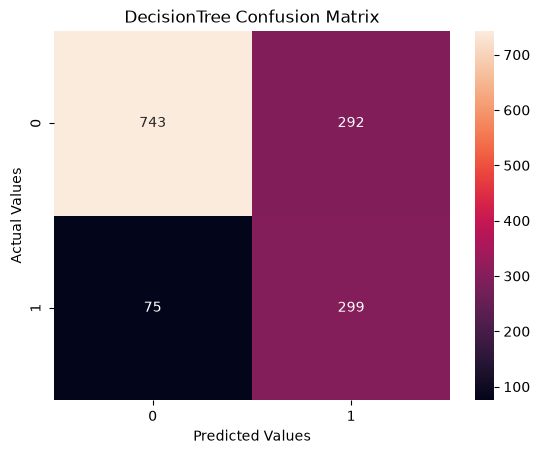

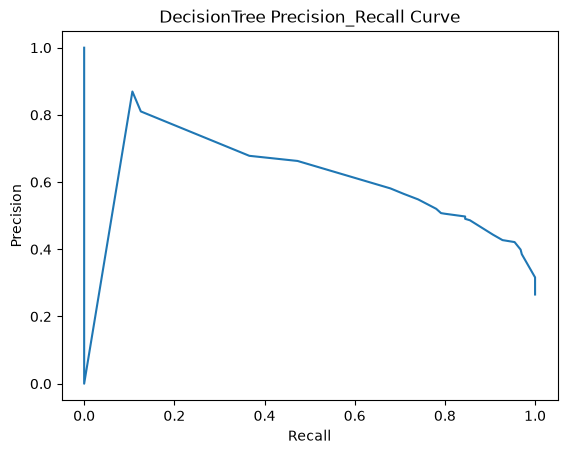

Accuracy: 0.74
 Precision: 0.51
 Recall: 0.78
 F1: 0.62

LogisticRegression Classification Report: 
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



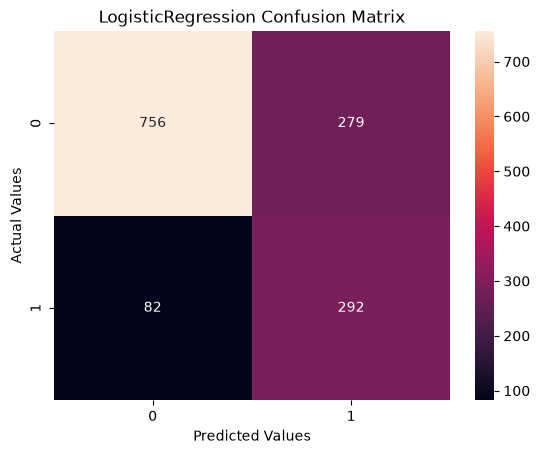

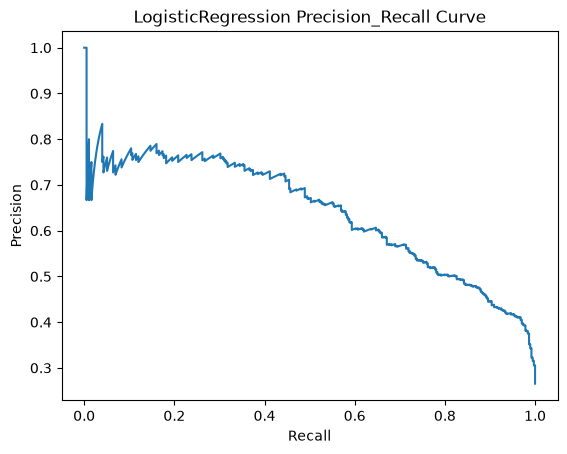

Accuracy: 0.76
 Precision: 0.53
 Recall: 0.80
 F1: 0.64

SVM Classification Report: 
              precision    recall  f1-score   support

           0       0.91      0.74      0.82      1035
           1       0.53      0.80      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



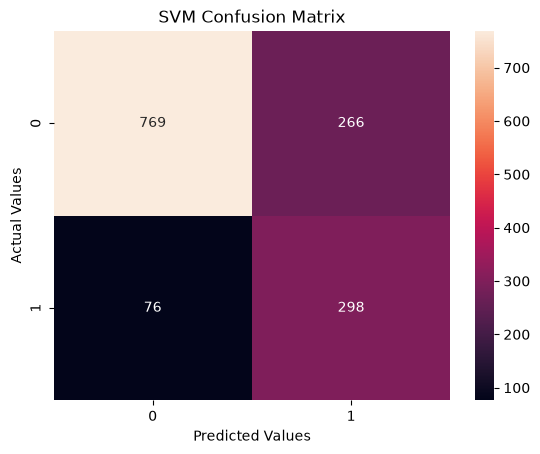

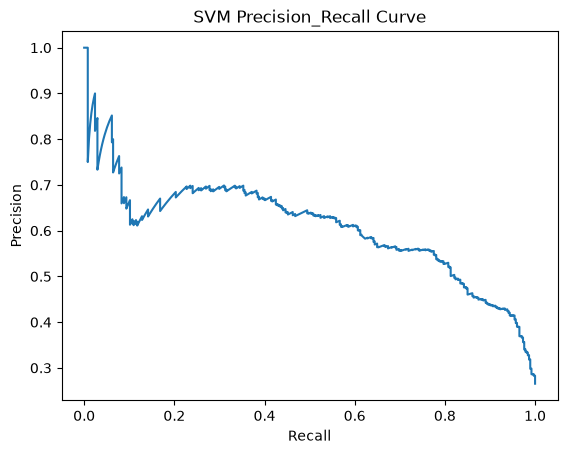

Accuracy: 0.72
 Precision: 0.48
 Recall: 0.81
 F1: 0.60

NaiveBayes Classification Report: 
              precision    recall  f1-score   support

           0       0.91      0.69      0.78      1035
           1       0.48      0.81      0.60       374

    accuracy                           0.72      1409
   macro avg       0.70      0.75      0.69      1409
weighted avg       0.80      0.72      0.74      1409



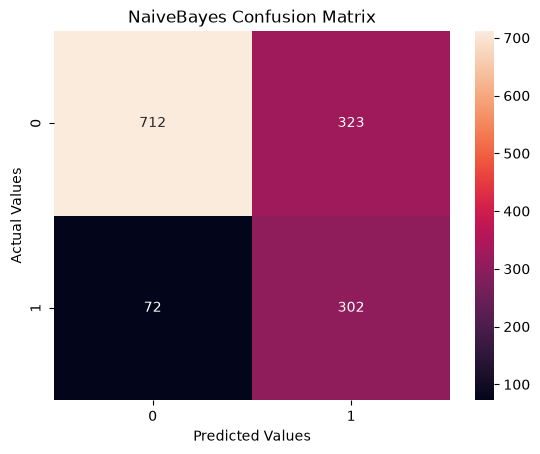

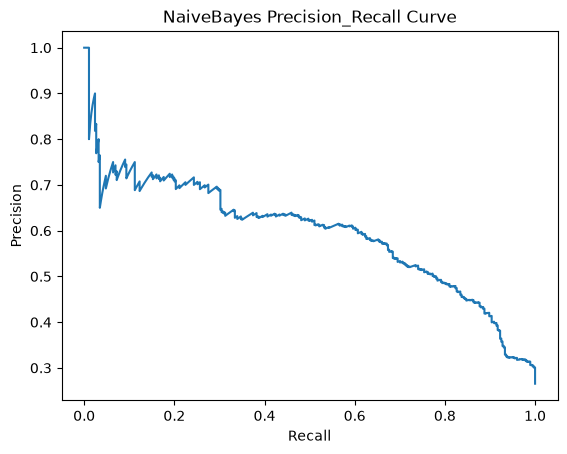

In [68]:
for model, pipe in models.items():
    if model in top_models:
        model_evaluation(model, pipe, X_test, y_test)

In [69]:
#Hyper Parameter Tuning
from scipy.stats import loguniform
param_dist_nb = {
    "classifier__var_smoothing": loguniform(1e-11, 1e-1),
}

search = RandomizedSearchCV(
    models["NaiveBayes"],
    param_distributions=param_dist_nb,
    n_iter=15,                       # 15 random combinations
    scoring="average_precision",     # PR-AUC, same metric you've been comparing on
    cv=cv,                           # your existing StratifiedKFold
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

search.fit(X_train, y_train)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...aussianNB())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.",{'classifier__var_smoothing': <scipy.stats....00261A6DD6490>}
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_``

Accuracy: 0.70
 Precision: 0.47
 Recall: 0.83
 F1: 0.60

Tuned Model Classification Report: 
              precision    recall  f1-score   support

           0       0.92      0.66      0.77      1035
           1       0.47      0.83      0.60       374

    accuracy                           0.70      1409
   macro avg       0.69      0.74      0.68      1409
weighted avg       0.80      0.70      0.72      1409



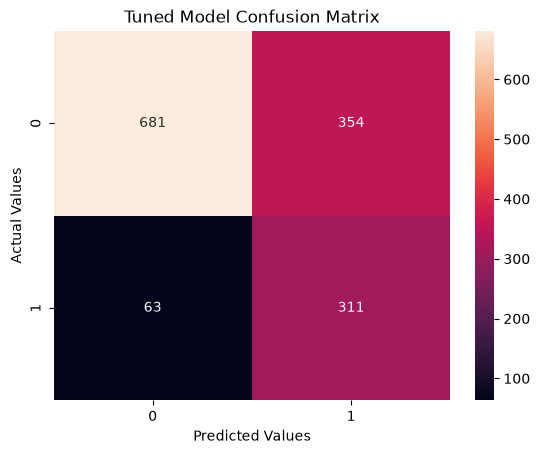

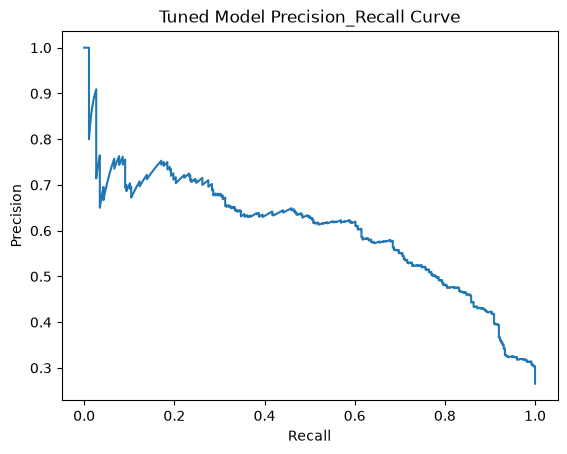

In [70]:
bsg = search.best_estimator_
model_evaluation('Tuned Model', search.best_estimator_, X_test, y_test)

In [71]:
print("Best settings:", search.best_params_)
print("Best CV PR-AUC:", round(search.best_score_, 3))

Best settings: {'classifier__var_smoothing': np.float64(0.05001479828856919)}
Best CV PR-AUC: 0.627


Accuracy: 0.74
 Precision: 0.51
 Recall: 0.78
 F1: 0.62

Logistic Regression Classification Report: 
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



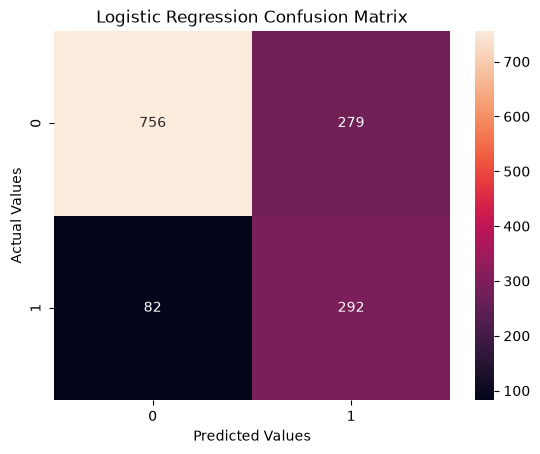

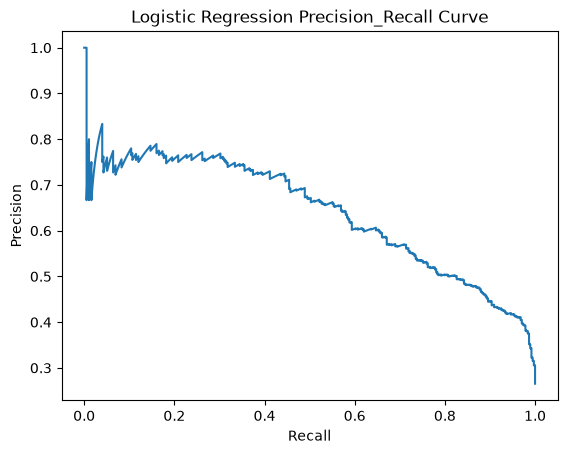

In [72]:
model_evaluation('Logistic Regression', models["LogisticRegression"], X_test, y_test)

In [73]:
ld_model = models["LogisticRegression"]

Threshold: 0.595 | precision: 0.582 | recall: 0.74 | F1: 0.651
Accuracy: 0.77
 Precision: 0.56
 Recall: 0.72
 F1: 0.63

LogisticRegression Classification Report: 
              precision    recall  f1-score   support

           0       0.89      0.79      0.84      1035
           1       0.56      0.72      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



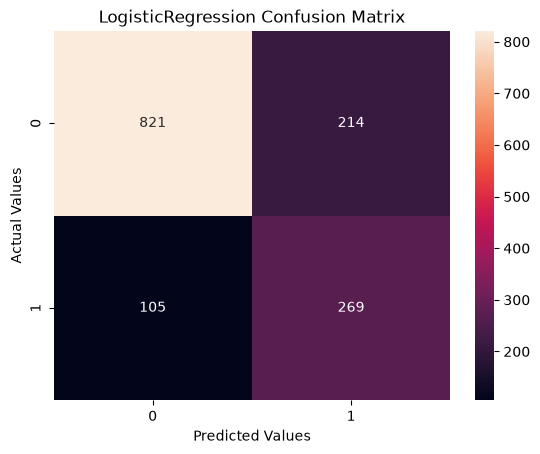

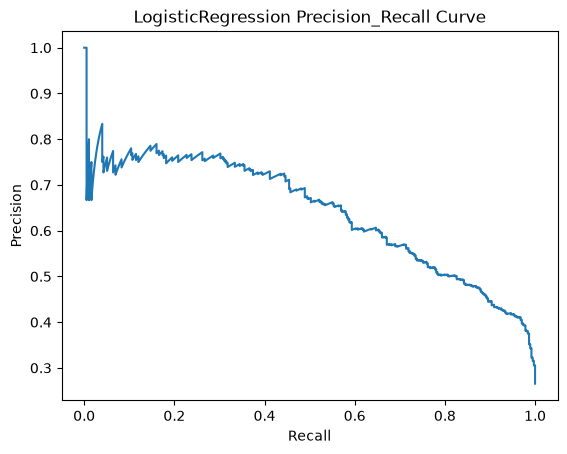

In [74]:
from sklearn.model_selection import cross_val_predict

# 1. Out-of-fold risk scores on the TRAINING data
train_prob = cross_val_predict(ld_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# 2. Precision and recall at every threshold
precisions, recalls, thresholds = precision_recall_curve(y_train, train_prob)

# 3. F1: multiply precision and recall, don't subtract
f1 = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)

# 4. Best threshold (the last point has no threshold, so skip it)
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]
print("Threshold:", round(best_threshold, 3),
      "| precision:", round(precisions[best], 3),
      "| recall:", round(recalls[best], 3),
      "| F1:", round(f1[best], 3))

# 5. Check it once on the test set
model_evaluation("LogisticRegression", ld_model, X_test, y_test, best_threshold)

In [75]:
!pip install shap
import shap

In [76]:
lr = models["LogisticRegression"]
lr.fit(X_train, y_train)                      # skip if already fitted

prep = lr.named_steps["preprocessor"]
clf = lr.named_steps["classifier"]

# 1. Preprocess the data the same way the model saw it
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]   # remove "num__" / "cat__" prefixes
X_train_t = pd.DataFrame(prep.transform(X_train), columns=feature_names)
X_test_t = pd.DataFrame(prep.transform(X_test), columns=feature_names)

# 2. Build the explainer from the classifier and background (training) data
explainer = shap.LinearExplainer(clf, X_train_t)

# 3. Calculate SHAP values for the test customers
shap_values = explainer(X_test_t)

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


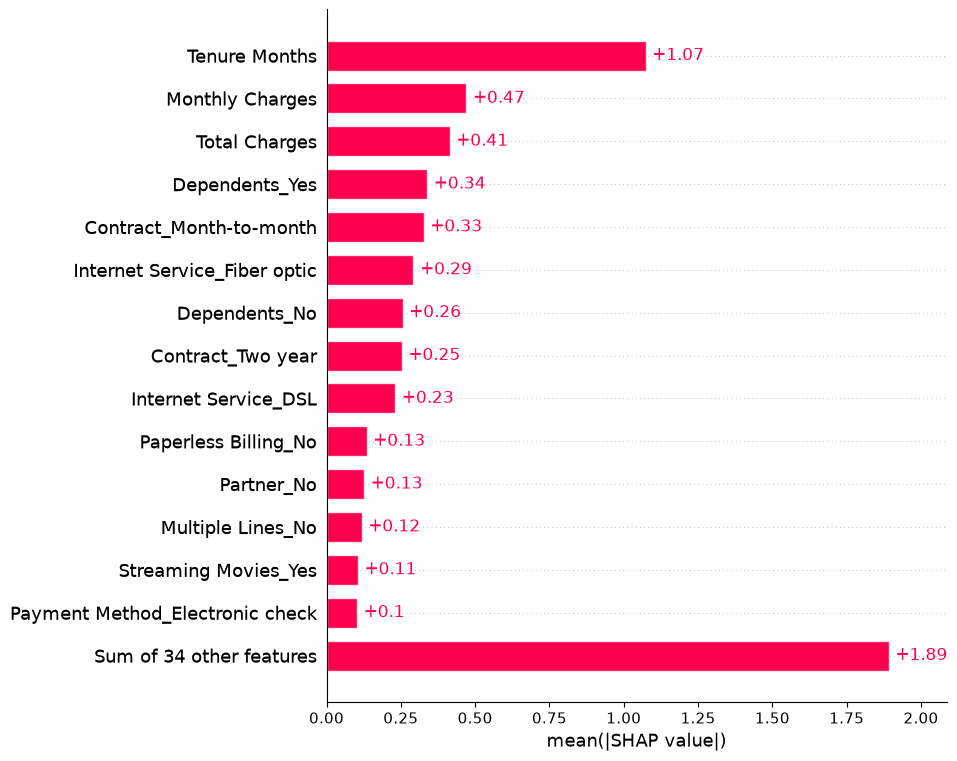

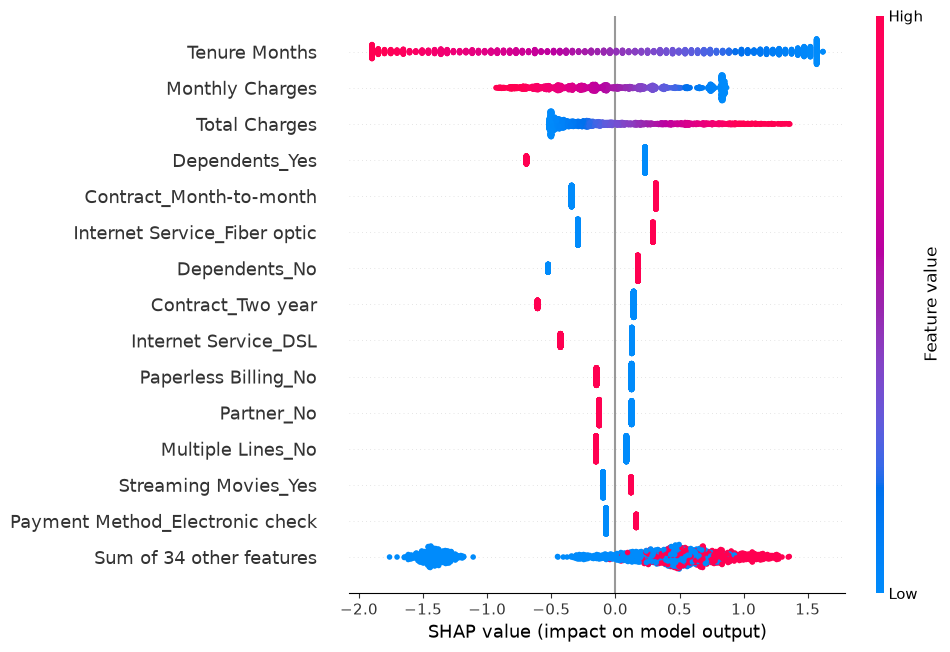

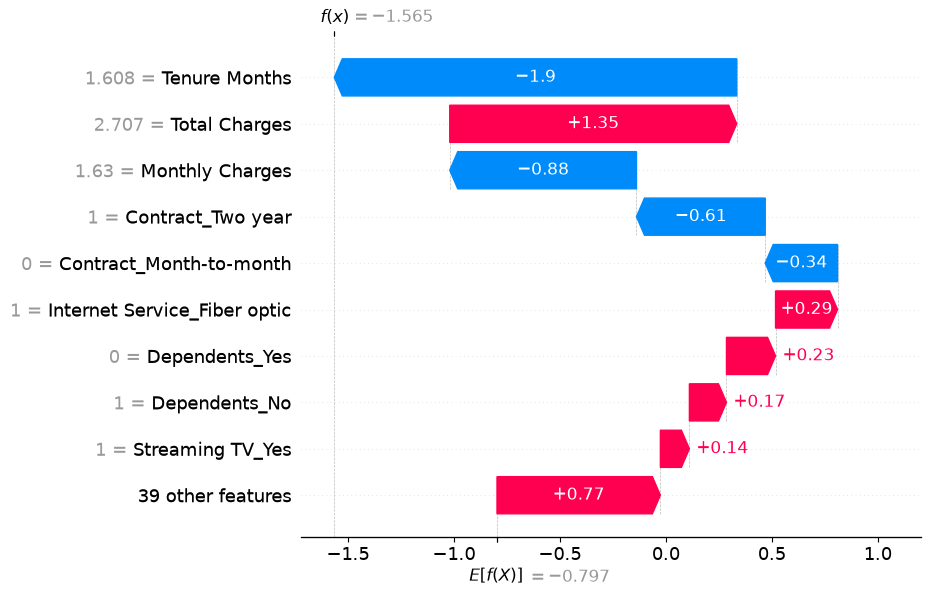

In [77]:
# Which features matter most overall
shap.plots.bar(shap_values, max_display=15)

# Which features matter, and in which direction
shap.plots.beeswarm(shap_values, max_display=15)

# Why one specific customer got their score
shap.plots.waterfall(shap_values[0])

In [78]:
#Get predictions from the best performing Logistic Regression model on the test set
y_pred = ld_model.predict(X_test)

In [79]:
#Create a dataframe to easily compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [80]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual']== 0) & (result_df['predicted']== 1)]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]

In [81]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")

False Positive : 279
False Negative : 82


In [82]:
import joblib

# Make sure the pipeline is fitted
ld_model.fit(X_train, y_train)

# Save the pipeline
joblib.dump(ld_model, "churn_model.joblib")

# Save the threshold and the expected input columns alongside it
joblib.dump({"threshold": float(best_threshold),
             "columns": X_train.columns.tolist()},
            "churn_config.joblib")

['churn_config.joblib']